# 05 · Waste Classifier (CNN + Transfer Learning)

**Goal:** take a photo of a waste item and tell which bin it goes in:
🟢 **Green (wet)**, 🔵 **Blue (dry)** or 🔴 **Red (hazardous)**.

**Approach:** transfer learning with **MobileNetV2** pretrained on ImageNet.
1. The pretrained convolutional layers are **frozen** and used as a feature extractor (each image → 1280 numbers).
2. Only a new small head `Dropout → Linear(1280 → 12)` is trained, with the same `CrossEntropyLoss + Adam` loop as the date-fruit ANN.
3. The full model is exported to **ONNX** so it runs in the browser (Kardhani Waste Command web app).

Dataset: *Garbage Classification (12 classes)*, 15,520 images (Kaggle, mirrored on Hugging Face).

In [1]:
import json, random, time
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset, Subset
from torchvision import datasets, transforms, models
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DATA_DIR = Path("data/garbage_classification")
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)
EXPORT = Path("export"); EXPORT.mkdir(exist_ok=True)
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_num_threads(8)
print("device:", device)

device: cpu


## 1. Dataset

`ImageFolder` reads the class name from the folder name. Two classes (*clothes*, *shoes*) have far more images than the rest,
so they are capped at 1,000 to keep the classes roughly balanced.

In [2]:
base = datasets.ImageFolder(DATA_DIR)
classes = base.classes
print(classes)

counts = np.bincount(base.targets)
for c, n in zip(classes, counts):
    print(f"{c:12s} {n}")

['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
battery      945
biological   985
brown-glass  607
cardboard    891
clothes      5325
green-glass  629
metal        769
paper        1050
plastic      865
shoes        1977
trash        697
white-glass  780


In [3]:
CAP = 1000
idx_by_class = {}
for i, t in enumerate(base.targets):
    idx_by_class.setdefault(t, []).append(i)

keep = []
for t, idxs in idx_by_class.items():
    random.shuffle(idxs)
    keep += idxs[:CAP]
labels = [base.targets[i] for i in keep]
print("images used:", len(keep))

# 70 / 15 / 15 split, stratified so every class appears in each split
train_idx, temp_idx = train_test_split(keep, test_size=0.30, stratify=labels, random_state=SEED)
temp_lab = [base.targets[i] for i in temp_idx]
val_idx, test_idx = train_test_split(temp_idx, test_size=0.50, stratify=temp_lab, random_state=SEED)
print(len(train_idx), len(val_idx), len(test_idx))

images used: 10168
7117 1525 1526


## 2. Bin mapping

The model predicts 12 classes; each class is mapped to one of the three bins of the SWM Rules, 2016.

In [4]:
BIN = {
    "biological": "green",                       # wet / compostable
    "battery": "red",                            # domestic hazardous
    "brown-glass": "blue", "green-glass": "blue", "white-glass": "blue",
    "cardboard": "blue", "paper": "blue", "plastic": "blue", "metal": "blue",
    "clothes": "blue", "shoes": "blue", "trash": "blue",   # dry
}
BINS = ["green", "blue", "red"]
bin_of = np.array([BINS.index(BIN[c]) for c in classes])

## 3. Transforms

* **Resize to 224×224** because MobileNetV2 was trained on that size.
* **Normalize** with ImageNet mean/std (the image version of `StandardScaler`).
* **Augmentation** (random crop, flip, small rotation, colour jitter) is used only for training images, to reduce overfitting.

In [5]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
plain_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
aug_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(0.2, 0.2, 0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
ds_plain = datasets.ImageFolder(DATA_DIR, transform=plain_tf)
ds_aug = datasets.ImageFolder(DATA_DIR, transform=aug_tf)

## 4. Pretrained MobileNetV2 as a frozen feature extractor

MobileNetV2 = stack of convolution blocks (edges → textures → shapes → objects) + a classifier for 1,000 ImageNet classes.
We keep the convolution part, **freeze it**, and remove the old classifier. Each image becomes a **1280-number feature vector**.

In [6]:
backbone = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V2)
backbone.classifier = nn.Identity()          # drop the 1000-class head -> output is 1280 features
for p in backbone.parameters():
    p.requires_grad = False                  # freeze
backbone.eval().to(device)

n_total = sum(p.numel() for p in backbone.parameters())
print(f"backbone parameters (frozen): {n_total:,}")

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to C:\Users\LENOVO/.cache\torch\hub\checkpoints\mobilenet_v2-7ebf99e0.pth


  0%|          | 0.00/13.6M [00:00<?, ?B/s]

  1%|          | 128k/13.6M [00:00<00:24, 578kB/s]

  2%|▏         | 256k/13.6M [00:00<00:16, 859kB/s]

  4%|▎         | 512k/13.6M [00:00<00:09, 1.46MB/s]

  7%|▋         | 1.00M/13.6M [00:00<00:05, 2.64MB/s]

... (3 outputs left out)

 63%|██████▎   | 8.50M/13.6M [00:01<00:00, 13.4MB/s]

 74%|███████▎  | 10.0M/13.6M [00:01<00:00, 12.4MB/s]

100%|██████████| 13.6M/13.6M [00:01<00:00, 11.1MB/s]

backbone parameters (frozen): 2,223,872


In [7]:
@torch.no_grad()
def extract(ds, idx, batch=64):
    loader = DataLoader(Subset(ds, idx), batch_size=batch, shuffle=False, num_workers=0)
    feats, ys = [], []
    for x, y in loader:
        feats.append(backbone(x.to(device)).cpu())
        ys.append(y)
    return torch.cat(feats), torch.cat(ys)

t0 = time.time()
Xtr_a, ytr_a = extract(ds_plain, train_idx)      # clean copy of training images
Xtr_b, ytr_b = extract(ds_aug, train_idx)        # augmented copy of training images
Xva, yva = extract(ds_plain, val_idx)
Xte, yte = extract(ds_plain, test_idx)
Xtr, ytr = torch.cat([Xtr_a, Xtr_b]), torch.cat([ytr_a, ytr_b])
print(f"feature extraction took {time.time()-t0:.0f} s")
print(Xtr.shape, Xva.shape, Xte.shape)

feature extraction took 459 s
torch.Size([14234, 1280]) torch.Size([1525, 1280]) torch.Size([1526, 1280])


## 5. The new head (the only part we train)

`Dropout(0.2) → Linear(1280 → 12)`: about 15k trainable parameters, versus 2.2 million frozen ones.
Loss and optimiser are the same as the date-fruit classifier: `CrossEntropyLoss` on raw logits + `Adam`.

In [8]:
head = nn.Sequential(
    nn.Dropout(0.2),
    nn.Linear(1280, len(classes)),       # 12 logits (no softmax: CrossEntropyLoss applies it)
).to(device)
print("trainable parameters:", sum(p.numel() for p in head.parameters()))

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(head.parameters(), lr=1e-3, weight_decay=1e-4)

train_loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=64, shuffle=True)
val_loader = DataLoader(TensorDataset(Xva, yva), batch_size=256)

trainable parameters: 15372


In [9]:
EPOCHS = 30
hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_acc, best_state = 0, None

for epoch in range(EPOCHS):
    head.train()
    tl, tc, tn = 0, 0, 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()              # 1. clear old gradients
        out = head(xb)                     # 2. forward pass
        loss = criterion(out, yb)          # 3. loss
        loss.backward()                    # 4. backprop
        optimizer.step()                   # 5. params update
        tl += loss.item() * len(yb); tc += (out.argmax(1) == yb).sum().item(); tn += len(yb)

    head.eval()
    vl, vc, vn = 0, 0, 0
    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            out = head(xb)
            vl += criterion(out, yb).item() * len(yb); vc += (out.argmax(1) == yb).sum().item(); vn += len(yb)

    hist["train_loss"].append(tl / tn); hist["val_loss"].append(vl / vn)
    hist["train_acc"].append(tc / tn); hist["val_acc"].append(vc / vn)
    if vc / vn > best_acc:
        best_acc, best_state = vc / vn, {k: v.clone() for k, v in head.state_dict().items()}
    if epoch % 5 == 4 or epoch == 0:
        print(f"epoch {epoch+1:2d}  train loss {tl/tn:.3f} acc {tc/tn:.3f} | val loss {vl/vn:.3f} acc {vc/vn:.3f}")

head.load_state_dict(best_state)
torch.save(best_state, OUT / "best_waste_head.pt")
print(f"best validation accuracy: {best_acc:.3f}")

epoch  1  train loss 0.816 acc 0.828 | val loss 0.371 acc 0.912


epoch  5  train loss 0.194 acc 0.947 | val loss 0.187 acc 0.943


epoch 10  train loss 0.126 acc 0.966 | val loss 0.163 acc 0.950


epoch 15  train loss 0.100 acc 0.972 | val loss 0.152 acc 0.953


epoch 20  train loss 0.086 acc 0.978 | val loss 0.153 acc 0.948


epoch 25  train loss 0.080 acc 0.978 | val loss 0.146 acc 0.953


epoch 30  train loss 0.071 acc 0.981 | val loss 0.147 acc 0.955
best validation accuracy: 0.956


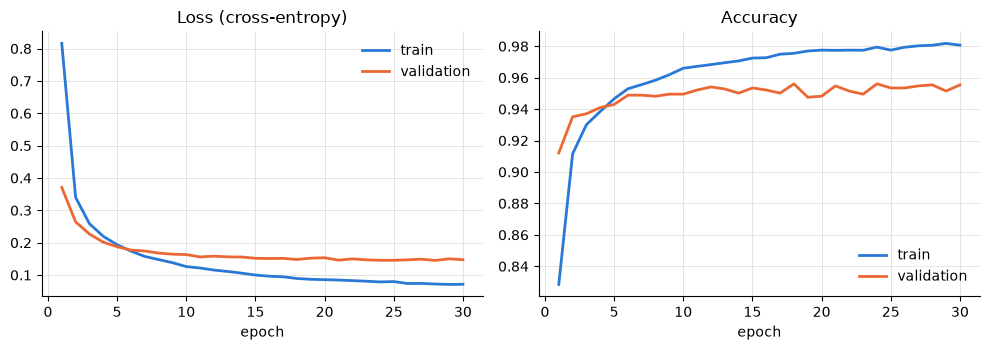

In [10]:
ep = range(1, EPOCHS + 1)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(ep, hist["train_loss"], color="#2a78d6", lw=2, label="train")
ax[0].plot(ep, hist["val_loss"], color="#eb6834", lw=2, label="validation")
ax[0].set_title("Loss (cross-entropy)"); ax[0].set_xlabel("epoch"); ax[0].legend(frameon=False)
ax[1].plot(ep, hist["train_acc"], color="#2a78d6", lw=2, label="train")
ax[1].plot(ep, hist["val_acc"], color="#eb6834", lw=2, label="validation")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend(frameon=False)
for a in ax:
    a.grid(color="#e1e0d9", lw=0.6); a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(OUT / "training_curves.png", dpi=200); plt.show()

## 6. Test-set evaluation

In [11]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score, f1_score

head.eval()
with torch.no_grad():
    pred = head(Xte.to(device)).argmax(1).cpu().numpy()
true = yte.numpy()

acc12 = accuracy_score(true, pred)
f1m = f1_score(true, pred, average="macro")
acc_bin = (bin_of[pred] == bin_of[true]).mean()
print(f"12-class test accuracy: {acc12:.3f}   macro F1: {f1m:.3f}")
print(f"bin-level (green/blue/red) accuracy: {acc_bin:.3f}")
print(classification_report(true, pred, target_names=classes, digits=3))

12-class test accuracy: 0.940   macro F1: 0.939
bin-level (green/blue/red) accuracy: 0.990
              precision    recall  f1-score   support

     battery      0.952     0.979     0.965       142
  biological      0.980     0.980     0.980       148
 brown-glass      0.978     0.956     0.967        91
   cardboard      0.985     0.955     0.970       134
     clothes      0.980     0.967     0.973       150
 green-glass      0.959     0.989     0.974        94
       metal      0.872     0.879     0.876       116
       paper      0.945     0.920     0.932       150
     plastic      0.846     0.846     0.846       130
       shoes      0.949     0.993     0.971       150
       trash      0.907     0.942     0.925       104
 white-glass      0.918     0.863     0.890       117

    accuracy                          0.940      1526
   macro avg      0.939     0.939     0.939      1526
weighted avg      0.941     0.940     0.940      1526



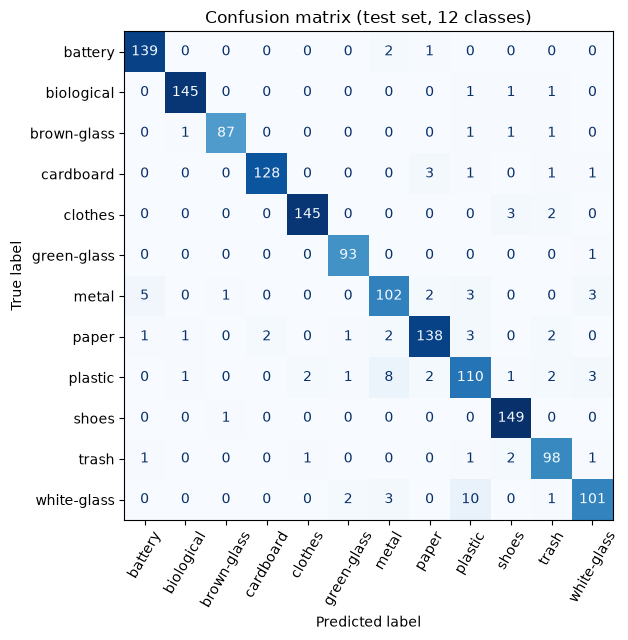

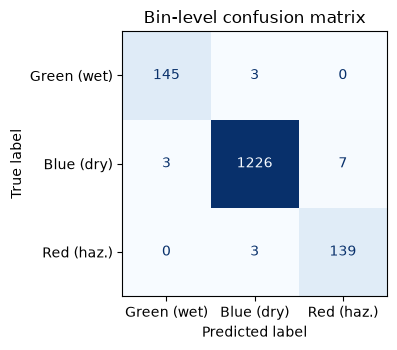

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))
ConfusionMatrixDisplay(confusion_matrix(true, pred), display_labels=classes).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=60)
ax.set_title("Confusion matrix (test set, 12 classes)")
plt.tight_layout(); plt.savefig(OUT / "confusion_matrix.png", dpi=200); plt.show()

cmb = confusion_matrix(bin_of[true], bin_of[pred], labels=[0, 1, 2])
fig, ax = plt.subplots(figsize=(4, 3.6))
ConfusionMatrixDisplay(cmb, display_labels=["Green (wet)", "Blue (dry)", "Red (haz.)"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Bin-level confusion matrix")
plt.tight_layout(); plt.savefig(OUT / "bin_confusion.png", dpi=200); plt.show()

## 7. Export the full model to ONNX

The exported model = **normalisation + frozen MobileNetV2 + trained head**. It takes an RGB image scaled to 0–1 (1×3×224×224)
and returns 12 logits, so the browser only has to resize the photo and divide by 255.

In [13]:
class WasteNet(nn.Module):
    def __init__(self, backbone, head):
        super().__init__()
        self.register_buffer("mean", torch.tensor(MEAN).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(STD).view(1, 3, 1, 1))
        self.backbone, self.head = backbone, head
    def forward(self, x):                       # x: 0..1 RGB
        return self.head(self.backbone((x - self.mean) / self.std))

full = WasteNet(backbone.cpu(), head.cpu()).eval()
dummy = torch.rand(1, 3, 224, 224)
torch.onnx.export(full, dummy, EXPORT / "waste_mobilenetv2.onnx", input_names=["image"], output_names=["logits"],
                  opset_version=17, dynamo=False)
json.dump({"classes": classes, "bins": {c: BIN[c] for c in classes}}, open(EXPORT / "labels.json", "w"), indent=1)
print(f"ONNX size: {(EXPORT / 'waste_mobilenetv2.onnx').stat().st_size / 2**20:.1f} MB")

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_27892\975167553.py:12: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(full, dummy, EXPORT / "waste_mobilenetv2.onnx", input_names=["image"], output_names=["logits"],


ONNX size: 8.5 MB


In [14]:
import onnxruntime as ort
sess = ort.InferenceSession(str(EXPORT / "waste_mobilenetv2.onnx"))
raw_tf = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor()])   # 0..1, no normalisation
ds_raw = datasets.ImageFolder(DATA_DIR, transform=raw_tf)

agree, n = 0, 200
for i in test_idx[:n]:
    x, _ = ds_raw[i]
    with torch.no_grad():
        p_torch = full(x[None]).argmax(1).item()
    p_onnx = sess.run(None, {"image": x[None].numpy()})[0].argmax(1).item()
    agree += p_torch == p_onnx
print(f"PyTorch vs ONNX agreement on {n} test images: {agree}/{n}")

PyTorch vs ONNX agreement on 200 test images: 200/200


## 8. A few test predictions

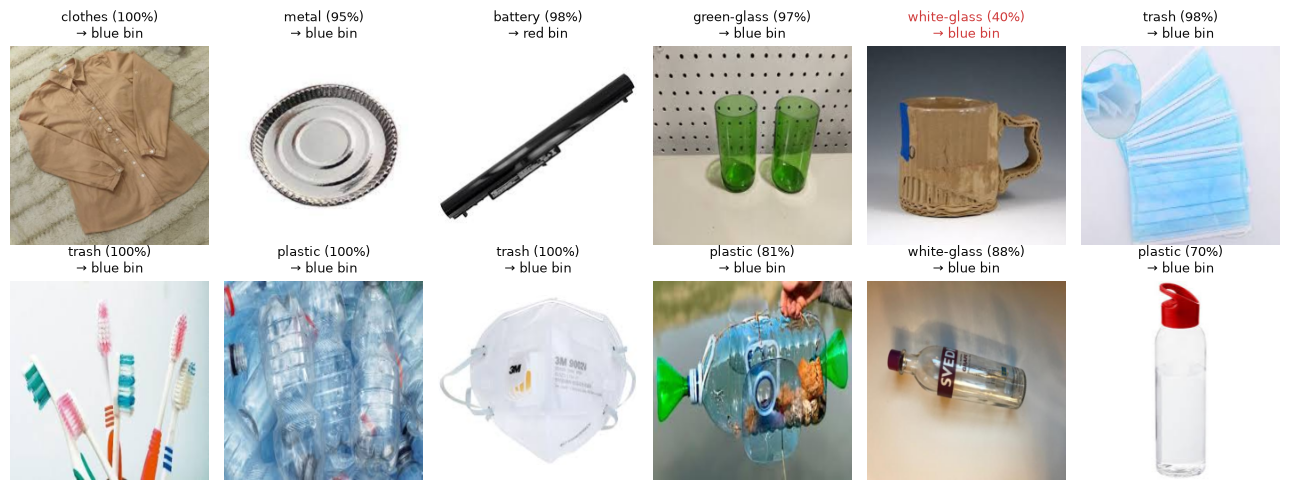

In [15]:
fig, axes = plt.subplots(2, 6, figsize=(13, 5))
sample = random.sample(test_idx, 12)
for ax, i in zip(axes.flat, sample):
    x, y = ds_raw[i]
    p = sess.run(None, {"image": x[None].numpy()})[0][0]
    prob = np.exp(p - p.max()); prob /= prob.sum()
    k = prob.argmax()
    ok = k == y
    ax.imshow(x.permute(1, 2, 0).numpy()); ax.axis("off")
    ax.set_title(f"{classes[k]} ({prob[k]*100:.0f}%)\n→ {BIN[classes[k]]} bin", fontsize=9, color="#0b0b0b" if ok else "#d03b3b")
plt.tight_layout(); plt.savefig(OUT / "sample_predictions.png", dpi=150); plt.show()

In [16]:
summary = {"images_used": len(keep), "train": len(train_idx), "val": len(val_idx), "test": len(test_idx),
           "test_acc_12": round(float(acc12), 4), "macro_f1": round(float(f1m), 4), "bin_acc": round(float(acc_bin), 4),
           "best_val_acc": round(float(best_acc), 4), "epochs": EPOCHS}
json.dump(summary, open(OUT / "summary.json", "w"), indent=1)
summary

{'images_used': 10168,
 'train': 7117,
 'val': 1525,
 'test': 1526,
 'test_acc_12': 0.9404,
 'macro_f1': 0.939,
 'bin_acc': 0.9895,
 'best_val_acc': 0.9561,
 'epochs': 30}